# 03 — Qualidade dos dados e “falhas” do estudo

O exemplo do professor trabalha com falhas de execução em experimentos computacionais. Aqui não há registro de execução experimental, falhas de máquina ou exclusões de tentativas: a base contém observações de alunos. A adaptação adequada é auditar integridade, critérios de inclusão e perdas entre a base completa e a análise.

**Importante:** não remover linhas automaticamente nem imputar valores sem uma justificativa definida. Este notebook mede os problemas e interrompe a preparação caso faltem campos essenciais.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

from visualizacoes import (
    configure_plots, plot_cell_counts, plot_factorial_cube,
    plot_protocol_flow, plot_quality_dashboard, save_figure,
)
from scipy import stats
from IPython.display import display

configure_plots()

DATA_NAME = "ai_student_impact_dataset.csv"
ROOT = next(
    (base for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "csv" / DATA_NAME).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        f"Não encontrei csv/{DATA_NAME} em nenhum diretório ancestral "
        f"do diretório atual: {Path.cwd()}"
    )
CSV_PATH = ROOT / "csv" / DATA_NAME
df = pd.read_csv(CSV_PATH)

required = {
    "Student_ID", "Major_Category", "Year_of_Study", "Pre_Semester_GPA",
    "Post_Semester_GPA", "Primary_Use_Case", "Anxiety_Level_During_Exams",
    "Traditional_Study_Hours",
}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes no CSV: {sorted(missing_columns)}")

df["Delta_GPA"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
PASSIVE_USE_CASES = {"Copywriting/Drafting", "Direct_Answer_Generation"}
df["A"] = np.where(df["Primary_Use_Case"].isin(PASSIVE_USE_CASES), 1, -1)
stem_junior = df.loc[
    (df["Major_Category"] == "STEM") & (df["Year_of_Study"] == "Junior")
].copy()

ANXIETY_Q2 = stem_junior["Anxiety_Level_During_Exams"].median()
STUDY_Q2 = stem_junior["Traditional_Study_Hours"].median()
stem_junior["B"] = np.where(
    stem_junior["Anxiety_Level_During_Exams"] > ANXIETY_Q2, 1, -1
)
stem_junior["C"] = np.where(
    stem_junior["Traditional_Study_Hours"] > STUDY_Q2, 1, -1
)
factorial = stem_junior.copy()

YATES = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
CELLS = [
    (a, b, c)
    for c in (-1, 1)
    for b in (-1, 1)
    for a in (-1, 1)
]
cell_number = {cell: number for number, cell in enumerate(CELLS, start=1)}
factorial["celula"] = [
    cell_number[(int(row.A), int(row.B), int(row.C))]
    for row in factorial[["A", "B", "C"]].itertuples(index=False)
]
groups = {
    key: frame["Delta_GPA"].to_numpy()
    for key, frame in factorial.groupby(["A", "B", "C"], sort=False)
}
cell_counts = factorial.groupby(["A", "B", "C"]).size()
if set(groups) != set(CELLS):
    raise ValueError("A classificação não produziu as oito células fatoriais.")
if factorial["Delta_GPA"].isna().any():
    raise ValueError("Há ΔGPA ausente; resolva os dados ausentes antes da análise.")

print(f"Arquivo: {CSV_PATH}")
print(f"Dataset completo: n={len(df):,}")
print(f"Recorte STEM + Junior: n={len(stem_junior):,}")
print(f"Analisados nas oito células: n={len(factorial):,}")
print(f"Cortes: ansiedade Q2={ANXIETY_Q2:g}; estudo Q2={STUDY_Q2:.2f} h")
print(f"Menor célula: n={cell_counts.min():,}")

configure_plots()


Arquivo: /home/wagner/pcc170/csv/ai_student_impact_dataset.csv
Dataset completo: n=50,000
Recorte STEM + Junior: n=3,279
Analisados nas oito células: n=3,279
Cortes: ansiedade Q2=4; estudo Q2=10.91 h
Menor célula: n=181


## Auditoria da base e do recorte

In [2]:

critical = [
    "Student_ID", "Major_Category", "Year_of_Study", "Pre_Semester_GPA",
    "Post_Semester_GPA", "Primary_Use_Case", "Anxiety_Level_During_Exams",
    "Traditional_Study_Hours",
]
invalid_gpa = (
    ~df["Pre_Semester_GPA"].between(0, 4)
    | ~df["Post_Semester_GPA"].between(0, 4)
)
audit = pd.DataFrame({
    "checagem": [
        "Linhas na base original",
        "IDs duplicados",
        "Linhas com campos essenciais ausentes",
        "GPA pré/pós fora do intervalo [0, 4]",
        "Alunos STEM + Junior",
        "Alunos incluídos nas oito células",
        "Fração do recorte incluída",
    ],
    "resultado": [
        len(df),
        int(df["Student_ID"].duplicated().sum()),
        int(df[critical].isna().any(axis=1).sum()),
        int(invalid_gpa.sum()),
        len(stem_junior),
        len(factorial),
        len(factorial) / len(stem_junior),
    ],
})
display(audit)
missing_by_field = df[critical].isna().sum().rename("ausentes").to_frame()
display(missing_by_field.loc[missing_by_field["ausentes"] > 0])

if df["Student_ID"].duplicated().any():
    raise ValueError("Há Student_ID duplicado; investigue antes de tratar cada linha como aluno.")
if df[critical].isna().any().any():
    raise ValueError("Há campos essenciais ausentes; defina o tratamento antes da análise.")
if invalid_gpa.any():
    raise ValueError("Há GPA fora do intervalo [0, 4]; valide os registros.")


,checagem,resultado
0,Linhas na base original,50000.0
1,IDs duplicados,0.0
2,Linhas com campos essenciais ausentes,0.0
3,"GPA pré/pós fora do intervalo [0, 4]",0.0
4,Alunos STEM + Junior,3279.0
5,Alunos incluídos nas oito células,3279.0
6,Fração do recorte incluída,1.0


,ausentes


## Indicadores visuais de integridade

Verificações com zero ocorrências aparecem como OK; qualquer ocorrência é destacada para investigação, não removida automaticamente.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Figura salva: 03_auditoria_integridade.png (PNG) e 03_auditoria_integridade.pdf (PDF)


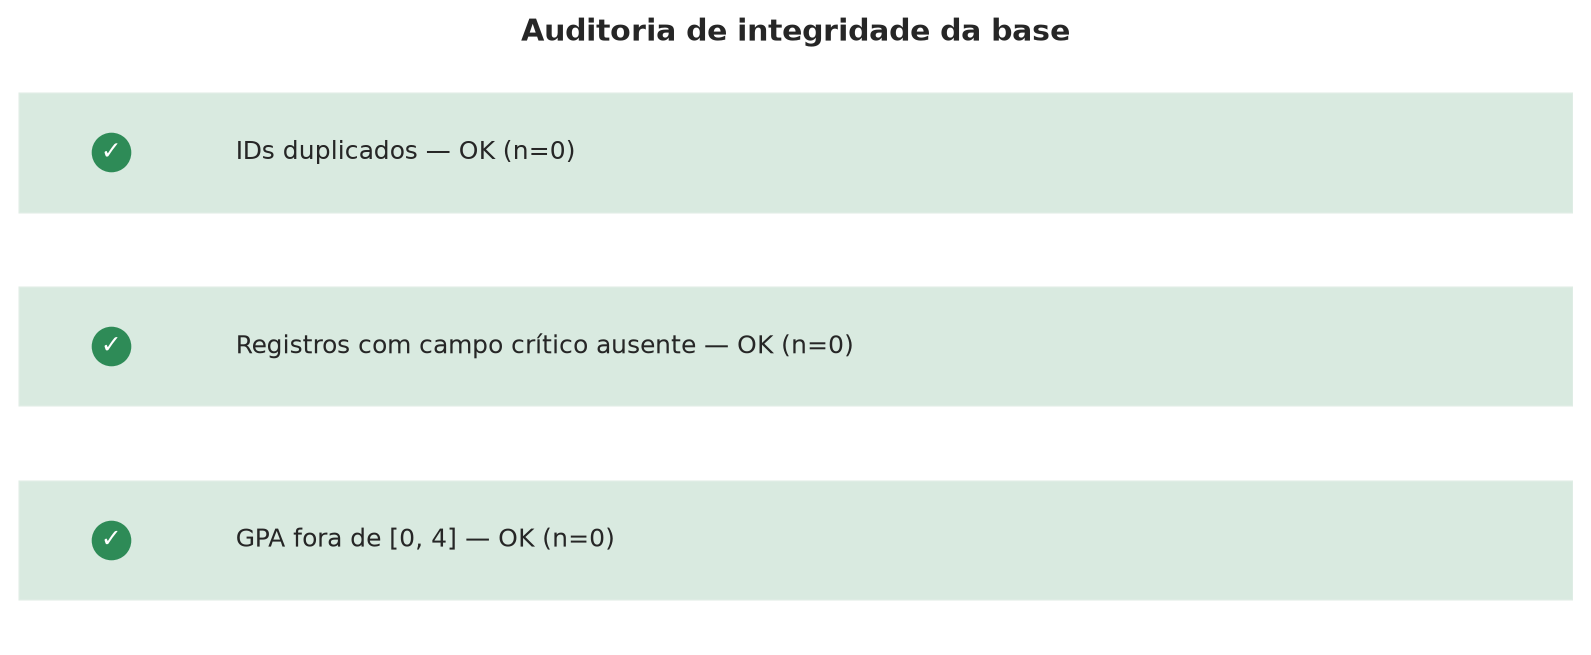

In [3]:
quality_labels = [
    "IDs duplicados",
    "Registros com campo crítico ausente",
    "GPA fora de [0, 4]",
]
quality_counts = [
    int(df["Student_ID"].duplicated().sum()),
    int(df[critical].isna().any(axis=1).sum()),
    int(invalid_gpa.sum()),
]
fig = plot_quality_dashboard(quality_labels, quality_counts)
save_figure(fig, "03_auditoria_integridade")


## Desbalanceamento: problema de precisão, não “falha” a corrigir por sorteio

In [4]:

cell_audit = (
    factorial.groupby(["A", "B", "C"])["Delta_GPA"]
    .agg(n="size", media="mean", desvio_padrao="std")
    .reindex(CELLS)
)
cell_audit.index = pd.Index(
    [f"{i + 1}: {cell}" for i, cell in enumerate(CELLS)], name="célula Yates"
)
display(cell_audit.round(3))
print(
    "Menor/maior n:",
    int(cell_audit["n"].min()),
    "/",
    int(cell_audit["n"].max()),
)


,n,media,desvio_padrao
célula Yates,,,
"1: (-1, -1, -1)",667,0.196,0.172
"2: (1, -1, -1)",210,0.152,0.198
"3: (-1, 1, -1)",576,0.201,0.184
"4: (1, 1, -1)",187,0.091,0.236
"5: (-1, -1, 1)",639,0.317,0.170
"6: (1, -1, 1)",235,0.252,0.176
"7: (-1, 1, 1)",584,0.323,0.173
"8: (1, 1, 1)",181,0.233,0.179


Menor/maior n: 181 / 667


## Precisão potencial por célula

Tamanhos diferentes implicam precisões diferentes; o gráfico documenta o desbalanceamento sem descartar alunos para forçar igualdade.

Figura salva: 03_tamanho_celulas.png (PNG) e 03_tamanho_celulas.pdf (PDF)


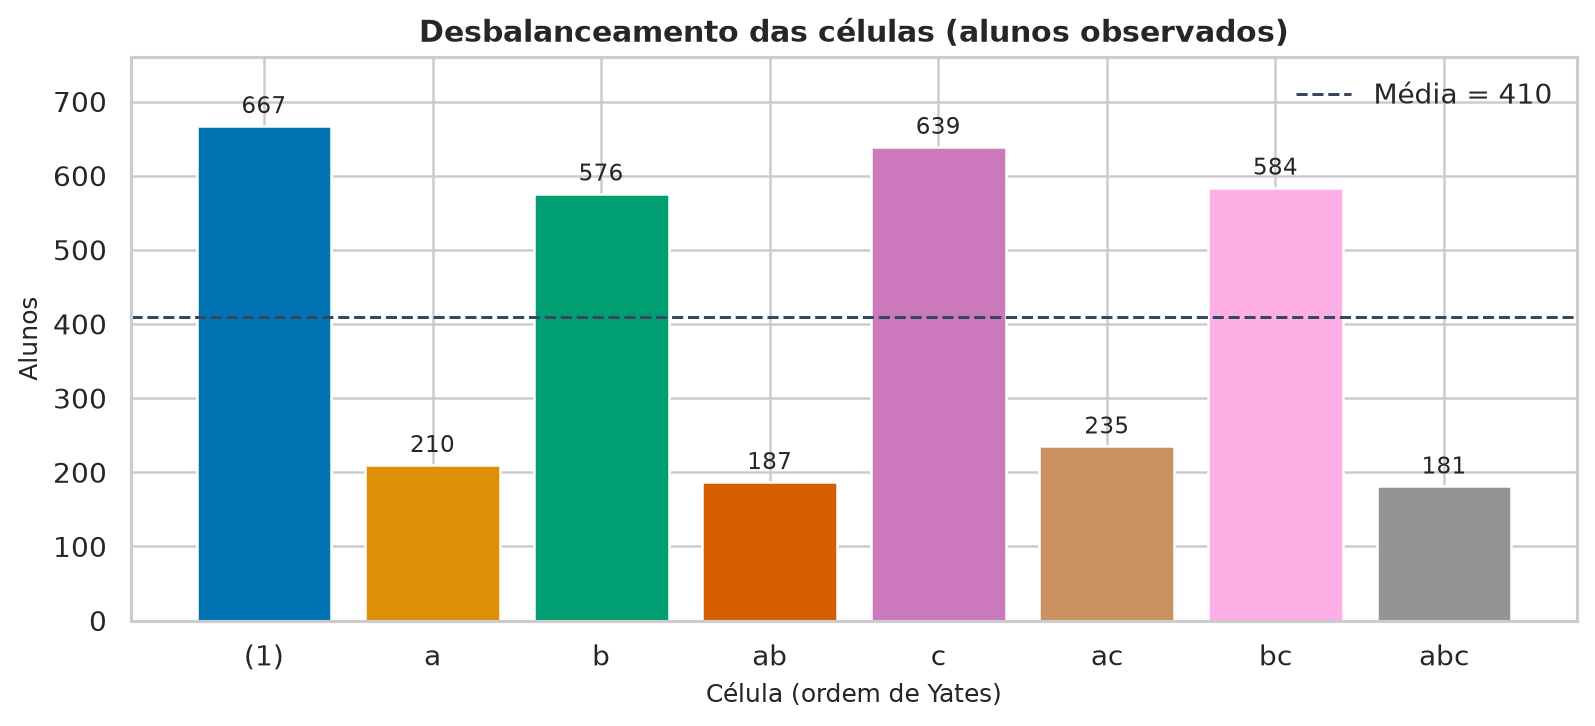

In [5]:
fig = plot_cell_counts(
    [int(len(groups[cell])) for cell in CELLS],
    YATES,
    title="Desbalanceamento das células (alunos observados)",
)
save_figure(fig, "03_tamanho_celulas")


## Decisões analíticas justificadas

1. A unidade é o aluno e o ID identifica a unidade; uma pessoa não pode ser contada várias vezes como réplica.
2. O recorte STEM + Junior e os níveis fatoriais são regras de inclusão e classificação; devem ser reportados junto aos resultados.
3. Os n das células não são equalizados descartando alunos. O modelo principal usa todos os 3.279 registros elegíveis.
4. Bootstrap estratificado mede incerteza dos contrastes, mas as reamostras não são novas observações independentes.
5. Se uma auditoria futura encontrar dados ausentes, IDs repetidos ou valores impossíveis, o notebook para e exige decisão explícita em vez de ocultar a falha.